# Part 10, notebook 4 of 5: the 200-image results

Companion to *When One Agent Is Not Enough*. The five notebooks follow the post in order. Each explains the idea with a daily-life picture, shows the real source, and runs it. **Cells marked "Your turn" are for you to change and rerun.**

| # | Notebook | Post section | Needs the model server? |
|---|---|---|---|
| 10a | `10a_three_ways` | Three ways to spend model contexts | two short live cells |
| 10b | `10b_supervisor_and_handoff` | A supervisor and two specialists | live cells (about 1 minute) |
| 10c | `10c_fanout_and_panel` | One sub-agent per box, and a panel | live cells (about 30 seconds) |
| 10d | `10d_the_200_image_results` | The results | no (reads the saved runs) |
| 10e | `10e_failures_and_tests` | What goes wrong | no |

**The picture.** A taste test with the same 200 dishes cooked five ways. Nobody guesses which tastes better: you count, and you also report how long each took and what the ingredients cost.

Everything here comes from the saved runs in `out/sub_runs*.jsonl` (about 2,000 image-runs). The model server is not needed.

In [1]:
import sys, json, os
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve()))     # this notebook lives in literate/, the code in notebooks/agentic-zero-to-advanced/
OUT = Path("..").resolve() / "out"
os.environ.setdefault("PART10_MODEL", "qwen3.8-27b")   # the model name the local vLLM server serves
import sub_agents as sa
import sub_summary as ss
%matplotlib inline
S = ss.summarize()
import matplotlib.pyplot as plt

## The table

`prec` and `recall` are over all boxes in the 200 held-out images (387 real voids). The Part 2 detector can only ever find about **21%** of them, so **no arm can have recall above 0.209**.

In [2]:
print(f"{'arm':11s}{'runs':>5}{'prec':>8}{'recall':>8}{'calls':>7}{'tokens':>8}{'biggest ctx':>13}{'sec/img*':>10}{'sub-agent failures':>20}")
for arm, a in S["arms"].items():
    p = a["pooled"]
    print(f"{arm:11s}{a['n_runs']:>5}{p['precision']:>8}{p['recall']:>8}{p['avg_calls']:>7}{p['avg_total_tokens']:>8}{p['avg_peak_prompt']:>13}{p['avg_seconds']:>10}{p['judge_failed']:>20}")
print("\n* seconds from the 200-image runs, 8 images at once, three processes sharing the GPU: queueing is included, compare roughly")

arm         runs    prec  recall  calls  tokens  biggest ctx  sec/img*  sub-agent failures
single         1   0.543   0.129   2.88    3151         1183      67.0                   0
supervisor     1   0.472   0.109   6.66    5948         1132     118.6                   0
batched        3   0.476   0.146    0.8     511          306      29.7                   3
fanout         3   0.597   0.135   2.76     873          200      12.3                   9
panel3         2   0.597   0.115   9.03    2934          243      27.1                  77

* seconds from the 200-image runs, 8 images at once, three processes sharing the GPU: queueing is included, compare roughly


## Is a difference real? Two checks

1. **The noise floor.** Run the same arm twice. At temperature 0 the kept boxes differ on only a few images.
2. **A bootstrap interval** on the difference against `batched` (resample the 200 images 2,000 times). An interval that contains 0 means: not distinguishable from nothing at this sample size.

In [3]:
print("same arm, two runs, images with a different kept set:", {k: f"{v['differ']}/{v['images']}" for k, v in S["agreement"].items() if "_vs_" not in k})
print("vs the batched judge, images with a different kept set:", {k.replace('_vs_batched', ''): f"{v['differ']}/{v['images']}" for k, v in S["agreement"].items() if k.endswith("_vs_batched")})
print()
for arm, dd in S["diff_vs_batched"].items():
    print(f"{arm:11s} minus batched   precision {dd['precision']}   recall {dd['recall']}")
print(f"{'supervisor':11s} minus single    precision {S['diff_vs_single']['precision']}   recall {S['diff_vs_single']['recall']}")

same arm, two runs, images with a different kept set: {'batched': '2/200', 'fanout': '7/200', 'panel3': '34/200'}
vs the batched judge, images with a different kept set: {'single': '28/200', 'supervisor': '50/200', 'fanout': '27/200', 'panel3': '37/200'}

single      minus batched   precision [0.015, 0.129]   recall [-0.031, -0.004]
supervisor  minus batched   precision [-0.114, 0.137]   recall [-0.06, -0.015]
fanout      minus batched   precision [0.07, 0.173]   recall [-0.02, -0.002]
panel3      minus batched   precision [0.067, 0.185]   recall [-0.045, -0.017]
supervisor  minus single    precision [-0.196, 0.081]   recall [-0.044, 0.005]


## Does it matter with more boxes?

Contexts grow with the number of boxes. The table groups images by how many candidate boxes the detector gave, and shows the **biggest context** each design held. The 8+ group is 12 images,
so its precision is a hint, not a result.

In [4]:
for arm in S["buckets"]:
    print(arm)
    for b, v in S["buckets"][arm].items():
        print(f"   {b:>4} boxes: image-runs {v['n']:4d}  precision {v['precision']}  recall {v['recall']}  biggest context {v['avg_peak_prompt']}")

single
      0 boxes: image-runs   55  precision None  recall 0.0  biggest context 817
    1-3 boxes: image-runs   91  precision 0.674  recall 0.162  biggest context 1096
    4-7 boxes: image-runs   42  precision 0.368  recall 0.182  biggest context 1534
     8+ boxes: image-runs   12  precision 0.625  recall 0.2  biggest context 2286
supervisor
      0 boxes: image-runs   55  precision None  recall 0.0  biggest context 710
    1-3 boxes: image-runs   91  precision 0.724  recall 0.11  biggest context 1129
    4-7 boxes: image-runs   42  precision 0.448  recall 0.169  biggest context 1392
     8+ boxes: image-runs   12  precision 0.258  recall 0.32  biggest context 2188
batched
      0 boxes: image-runs  165  precision None  recall 0.0  biggest context 0
    1-3 boxes: image-runs  273  precision 0.634  recall 0.182  biggest context 342
    4-7 boxes: image-runs  126  precision 0.352  recall 0.216  biggest context 495
     8+ boxes: image-runs   36  precision 0.306  recall 0.2  biggest c

## Your turn: choose what to plot

Pick a candidate-box bucket (`"0"`, `"1-3"`, `"4-7"`, `"8+"`) and a metric (`precision`, `recall`, `avg_peak_prompt`, `avg_total_tokens`, `avg_calls`) and rerun.

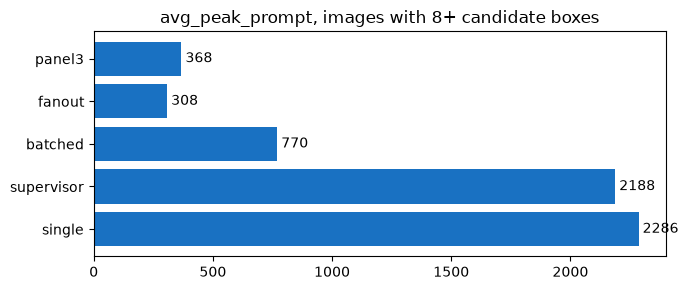

In [5]:
BUCKET = "8+"
METRIC = "avg_peak_prompt"

arms = [a for a in S["buckets"] if BUCKET in S["buckets"][a]]
vals = [S["buckets"][a][BUCKET][METRIC] or 0 for a in arms]
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(arms, vals, color="#1971c2")
ax.set_title(f"{METRIC}, images with {BUCKET} candidate boxes")
for i, v in enumerate(vals): ax.text(v, i, f" {v}", va="center")
plt.tight_layout(); plt.show()

## One image at a time: the latency check

The 200-image runs overlapped, so their seconds include waiting. `sub_latency.py` ran 20 images **strictly one after the other**, each arm alone.

In [6]:
lat = OUT / "sub_latency.json"
if lat.exists():
    L = json.loads(lat.read_text())
    print(f"first {len(L['images'])} held-out images that have at least one candidate box, one at a time\n")
    for arm, v in L["arms"].items():
        print(f"{arm:11s} mean {v['mean']:6.1f} s   median {v['median']:6.1f} s   slowest {v['max']:6.1f} s")
else:
    print("out/sub_latency.json is not there: run `uv run python sub_latency.py` (about 35 minutes)")

first 20 held-out images that have at least one candidate box, one at a time

single      mean   23.6 s   median   20.9 s   slowest   47.4 s
supervisor  mean   45.4 s   median   40.6 s   slowest   96.1 s
batched     mean   11.5 s   median   10.6 s   slowest   32.6 s
fanout      mean    5.0 s   median    4.5 s   slowest   10.2 s
